In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 1 — SETUP & IMPORTS
# ═══════════════════════════════════════════════════════════════════════════
import sys, warnings, os
warnings.filterwarnings("ignore")

from pathlib import Path
try:
    _HERE = Path(__file__).resolve().parent
except NameError:
    _HERE = Path(os.getcwd())

_ROOT = _HERE.parent if _HERE.name == "finding_threshold" else _HERE
_DOCS = _ROOT.parent
for _p in [str(_DOCS), str(_ROOT)]:
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

from market_analysis.config import PVD as PVD_CFG, OHLC_START_DATE, OHLC_END_DATE
from market_analysis.finding_threshold.pvd_threshold import run_pvd_threshold_analysis

print("✅ Imports OK")
print(f"   Root           : {_ROOT}")
print(f"   OHLC window    : {OHLC_START_DATE}  →  {OHLC_END_DATE}")
print(f"\n{'─'*55}")
print("  PVD CONFIG")
print(f"{'─'*55}")
for k, v in PVD_CFG.items():
    print(f"  {k:<28}: {v}")


✅ Imports OK
   Root           : c:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis
   OHLC window    : 2026-01-01  →  2026-09-23

───────────────────────────────────────────────────────
  PVD CONFIG
───────────────────────────────────────────────────────
  price_horizon_h             : 3
  volatility_window           : 15
  pvd_model_window            : 15
  atr_period                  : 10
  exhaustion_z_threshold      : -1.5
  expansion_z_threshold       : 1.5
  outcome_atr_multiplier      : 1.5
  outcome_horizon_days        : 10
  threshold_grid_start        : 0.1
  threshold_grid_stop         : 1.0
  threshold_grid_step         : 0.05
  min_signal_count            : 8
  n_bootstrap                 : 500
  random_seed                 : 42
  exhaustion_merge_unresolved : True


In [11]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 2 — PARAMETERS
# ═══════════════════════════════════════════════════════════════════════════
PRODUCT_CODE   = "BO"
MONTHS_BACK    = 7
FRONT_N_INSTR  = 5

# Exhaustion sweep — NEGATIVE values; code internally uses |z|
Z_GRID_NEG     = np.arange(-3.0, -0.20, 0.1)   # → |z| from 0.75 to 3.0

# Expansion analysis — POSITIVE values
Z_GRID_POS     = np.arange(0.2, 3.5, 0.1)

ATR_MULTIPLIER = 1.5    # ATR × this = target & stop distance
HORIZON_DAYS   = 10     # max future daily bars for outcome
MIN_N          = 8      # Low-N flag
N_BOOTSTRAP    = 500
RANDOM_SEED    = 42

print("=" * 60)
print("  PVD THRESHOLD ANALYSIS — PARAMETERS")
print("=" * 60)
print(f"  Product         : {PRODUCT_CODE}")
print(f"  History         : last {MONTHS_BACK} months")
print(f"  Front-N         : {FRONT_N_INSTR} spreads  +  {FRONT_N_INSTR} jumbos")
print(f"  ATR multiplier  : {ATR_MULTIPLIER}")
print(f"  Horizon         : {HORIZON_DAYS} daily bars")
print(f"  |z| sweep       : {abs(Z_GRID_NEG[-1]):.2f} → {abs(Z_GRID_NEG[0]):.2f}  "
      f"({len(Z_GRID_NEG)} steps)")
print(f"  Config ref |z|  : {abs(PVD_CFG['exhaustion_z_threshold']):.2f}")
print(f"  Expansion |z|   : {Z_GRID_POS[0]:.2f} → {Z_GRID_POS[-1]:.2f}")
print("=" * 60)


  PVD THRESHOLD ANALYSIS — PARAMETERS
  Product         : BO
  History         : last 7 months
  Front-N         : 5 spreads  +  5 jumbos
  ATR multiplier  : 1.5
  Horizon         : 10 daily bars
  |z| sweep       : 0.30 → 3.00  (28 steps)
  Config ref |z|  : 1.50
  Expansion |z|   : 0.20 → 3.40



########################################################################
#  STRUCTURE : SPREAD  --  BO
########################################################################

  INSTRUMENT : BOV26-Z26  (SPREAD)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (187 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 54   SUCCESS=17  FAILURE=21  UNRESOLVED=16
    UP_TREND_EXHAUSTI

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,54,0.611,"[0.463, 0.741]",1.000,0.759,--,1.000,33,21,0,0,False
1,0.400,49,0.653,"[0.536, 0.788]",0.970,0.780,0.269,1.069,32,17,1,4,False
2,0.500,47,0.638,"[0.521, 0.778]",0.909,0.750,0.145,1.044,30,17,3,4,False
3,0.600,42,0.619,"[0.531, 0.786]",0.788,0.693,0.030,1.013,26,16,7,5,False
4,0.700,33,0.636,"[0.553, 0.814]",0.636,0.636,0.065,1.041,21,12,12,9,False
5,0.800,32,0.656,"[0.554, 0.871]",0.636,0.646,0.112,1.074,21,11,12,10,False
6,0.900,31,0.645,"[0.542, 0.867]",0.606,0.625,0.081,1.056,20,11,13,10,False
7,1.000,21,0.571,"[0.464, 0.857]",0.364,0.444,-0.065,0.935,12,9,21,12,False
8,1.100,19,0.526,"[0.404, 0.857]",0.303,0.385,-0.128,0.861,10,9,23,12,False
9,1.200,14,0.571,"[0.360, 0.882]",0.242,0.340,-0.048,0.935,8,6,25,15,False


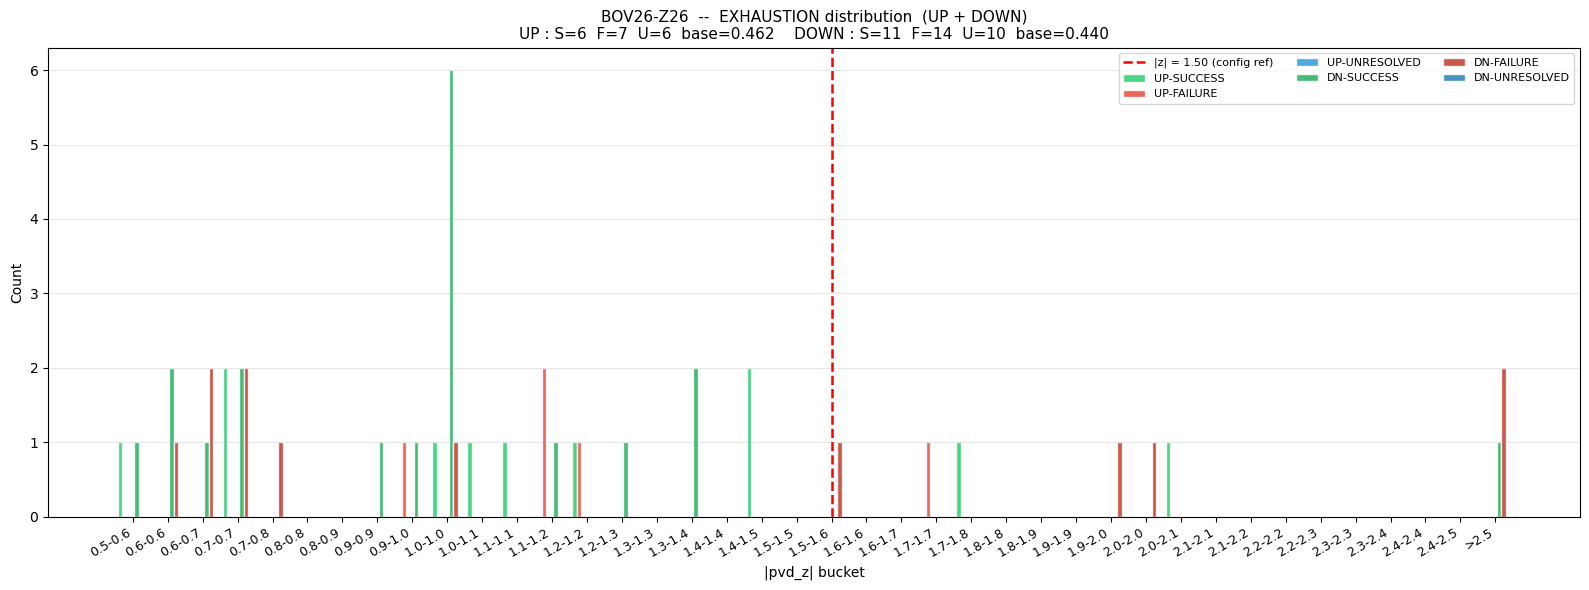

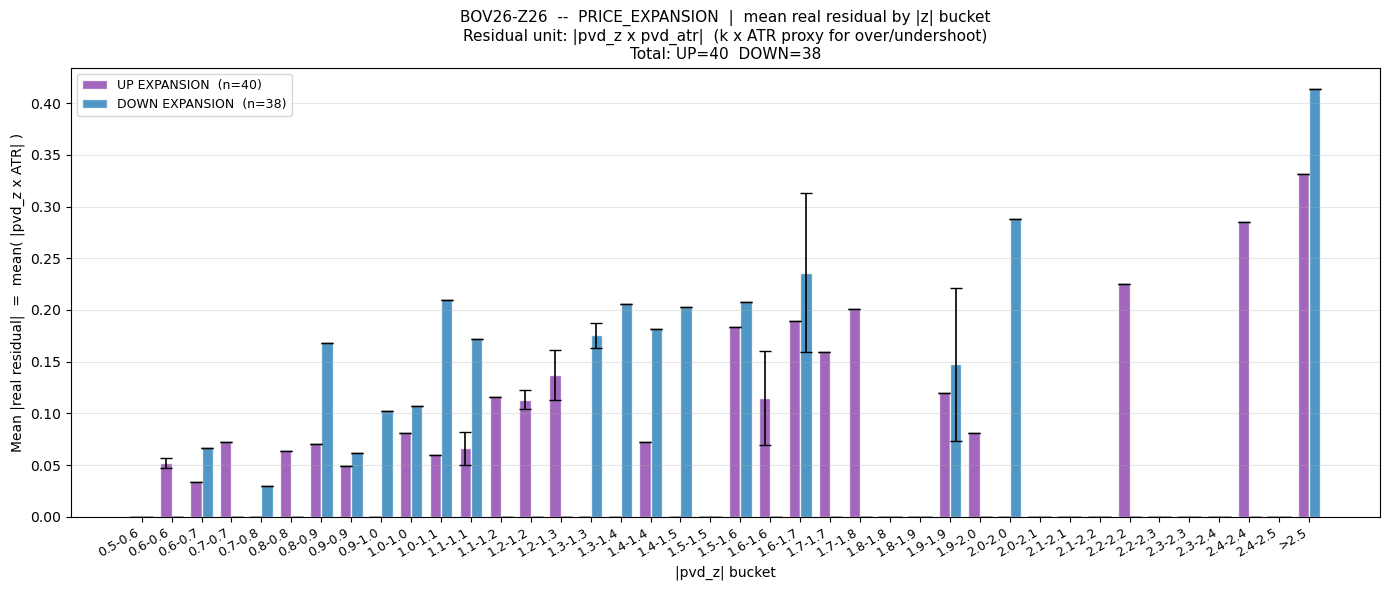

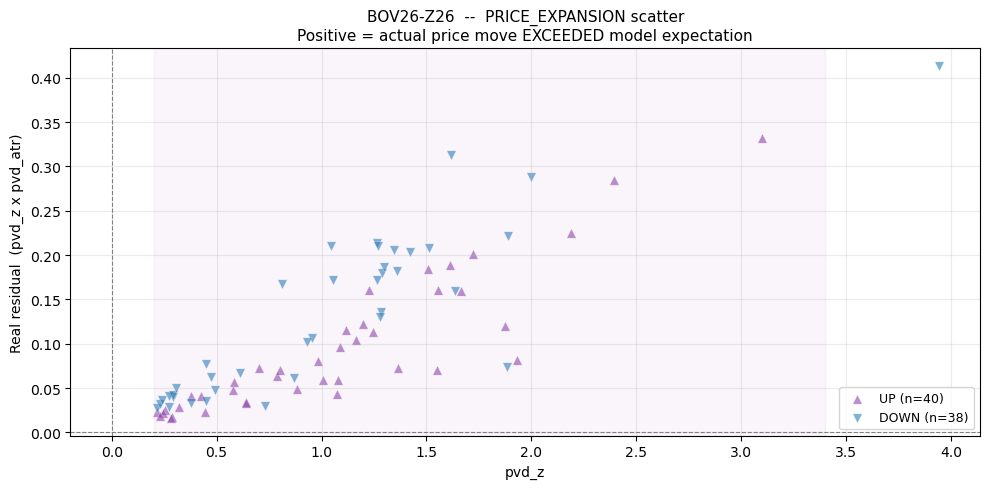


  INSTRUMENT : BOZ26-F27  (SPREAD)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (187 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 59   SUCCESS=19  FAILURE=13  UNRESOLVED=27
    UP_TREND_EXHAUSTION         : S=11  F=8  U=11  total=30
    DOWN_TREND_EXHAUSTION       : S=8  F=5  U=16  total=29

  -- EXPANSION SIGNALS -------------------------------------------
    UP_PRIC

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,59,0.780,"[0.695, 0.898]",1.000,0.876,--,1.000,46,13,0,0,False
1,0.400,53,0.830,"[0.755, 0.938]",0.957,0.889,0.362,1.065,44,9,2,4,False
2,0.500,47,0.851,"[0.798, 0.933]",0.870,0.860,0.341,1.092,40,7,6,6,False
3,0.600,40,0.900,"[0.837, 0.972]",0.783,0.837,0.421,1.154,36,4,10,9,False
4,0.700,37,0.946,"[0.884, 1.000]",0.761,0.843,0.520,1.213,35,2,11,11,False
5,0.800,33,0.939,"[0.871, 1.000]",0.674,0.785,0.434,1.205,31,2,15,11,False
6,0.900,30,0.933,"[0.867, 1.000]",0.609,0.737,0.377,1.197,28,2,18,11,False
7,1.000,29,0.931,"[0.862, 1.000]",0.587,0.720,0.359,1.194,27,2,19,11,False
8,1.100,25,0.920,"[0.844, 1.000]",0.500,0.648,0.290,1.180,23,2,23,11,False
9,1.200,20,0.900,"[0.826, 1.000]",0.391,0.545,0.208,1.154,18,2,28,11,False


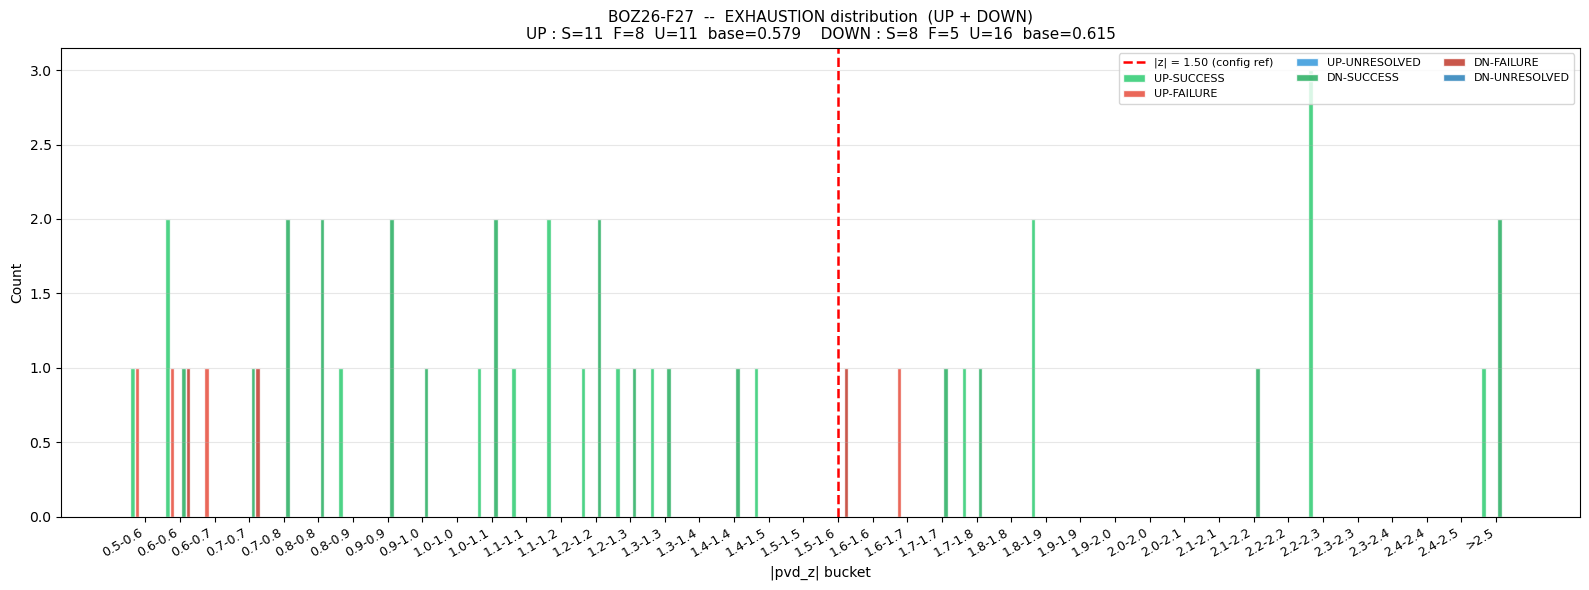

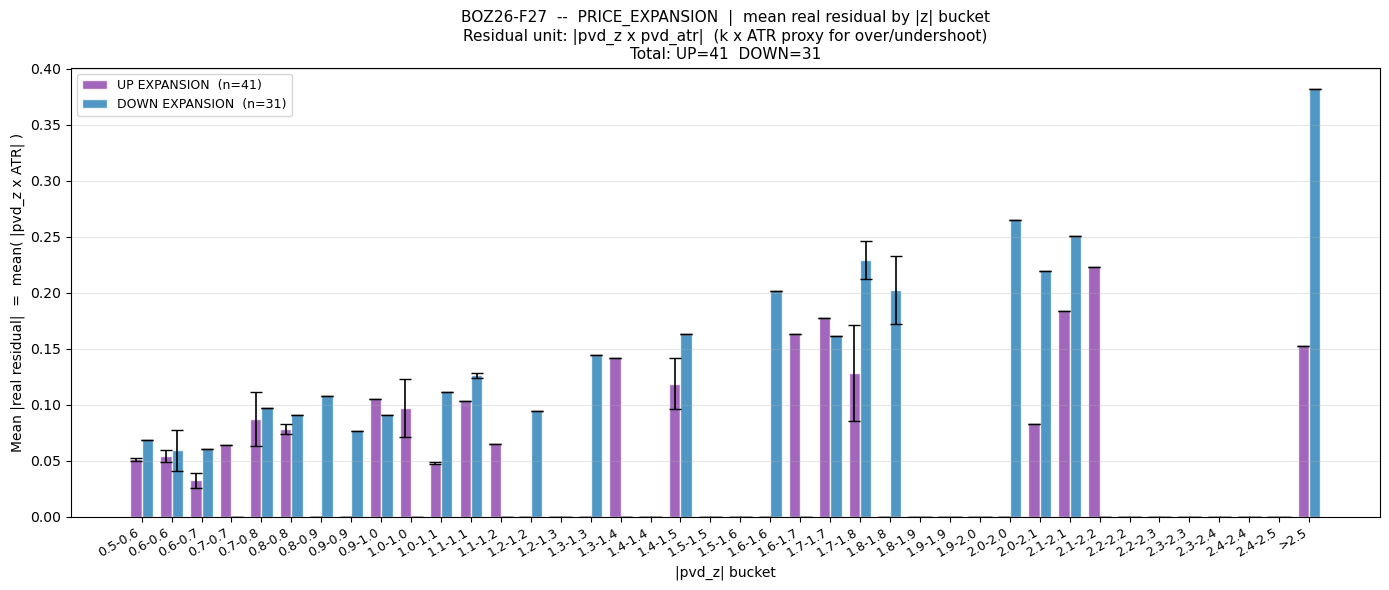

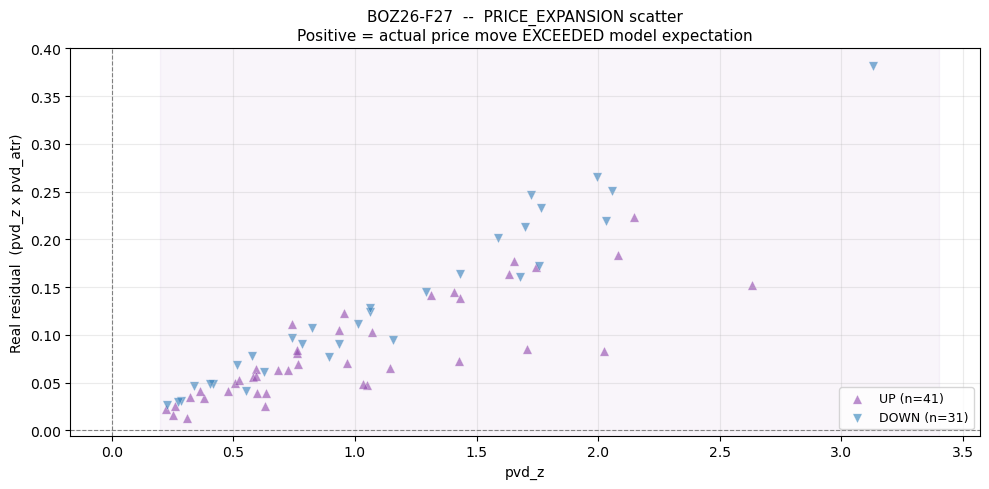


  INSTRUMENT : BOF27-H27  (SPREAD)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (186 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 57   SUCCESS=10  FAILURE=12  UNRESOLVED=35
    UP_TREND_EXHAUSTION         : S=6  F=10  U=12  total=28
    DOWN_TREND_EXHAUSTION       : S=4  F=2  U=23  total=29

  -- EXPANSION SIGNALS -------------------------------------------
    UP_PRIC

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,57,0.789,"[0.693, 0.947]",1.000,0.882,--,1.000,45,12,0,0,False
1,0.400,55,0.800,"[0.714, 0.962]",0.978,0.880,0.135,1.013,44,11,1,1,False
2,0.500,49,0.816,"[0.735, 0.958]",0.889,0.851,0.163,1.034,40,9,5,3,False
3,0.600,43,0.791,"[0.700, 0.954]",0.756,0.773,0.005,1.002,34,9,11,3,False
4,0.700,41,0.780,"[0.682, 0.951]",0.711,0.744,-0.035,0.989,32,9,13,3,False
5,0.800,39,0.769,"[0.667, 0.948]",0.667,0.714,-0.073,0.974,30,9,15,3,False
6,0.900,36,0.750,"[0.635, 0.943]",0.600,0.667,-0.127,0.950,27,9,18,3,False
7,1.000,30,0.800,"[0.667, 0.966]",0.533,0.640,0.027,1.013,24,6,21,6,False
8,1.100,24,0.750,"[0.625, 0.955]",0.400,0.522,-0.083,0.950,18,6,27,6,False
9,1.200,20,0.750,"[0.595, 0.939]",0.333,0.462,-0.071,0.950,15,5,30,7,False


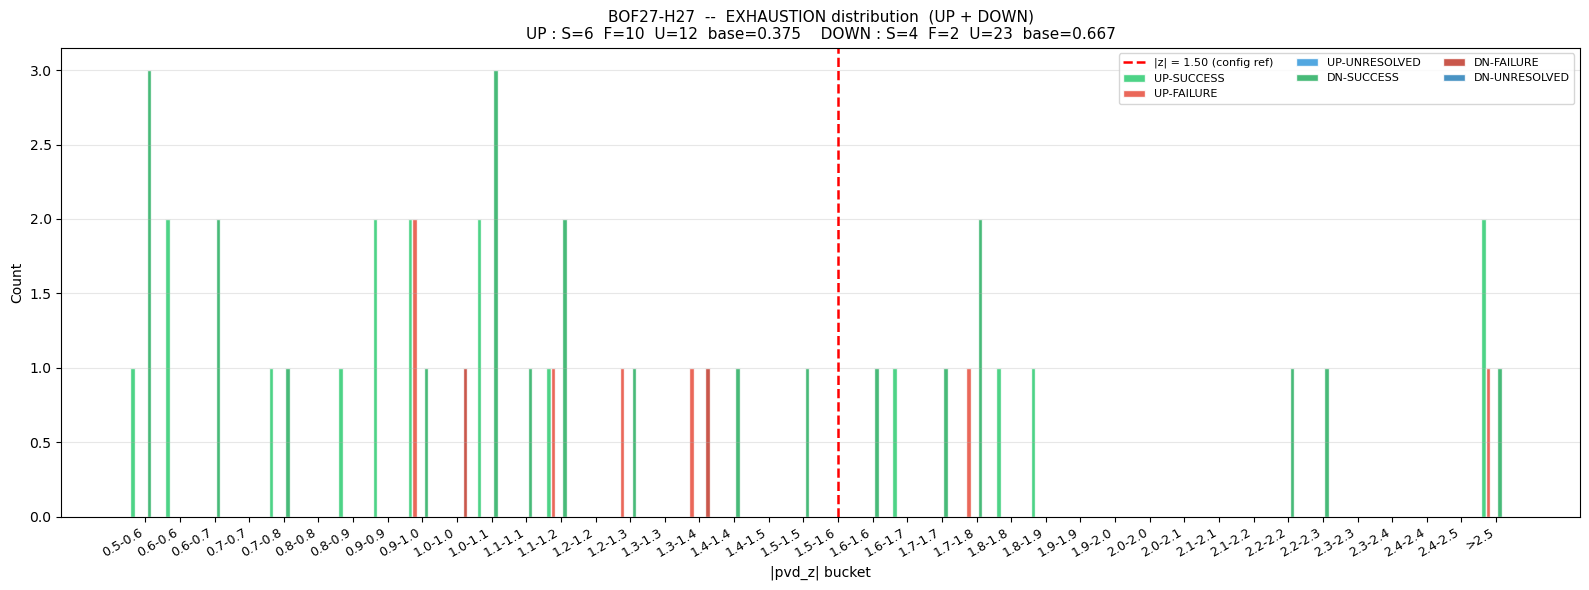

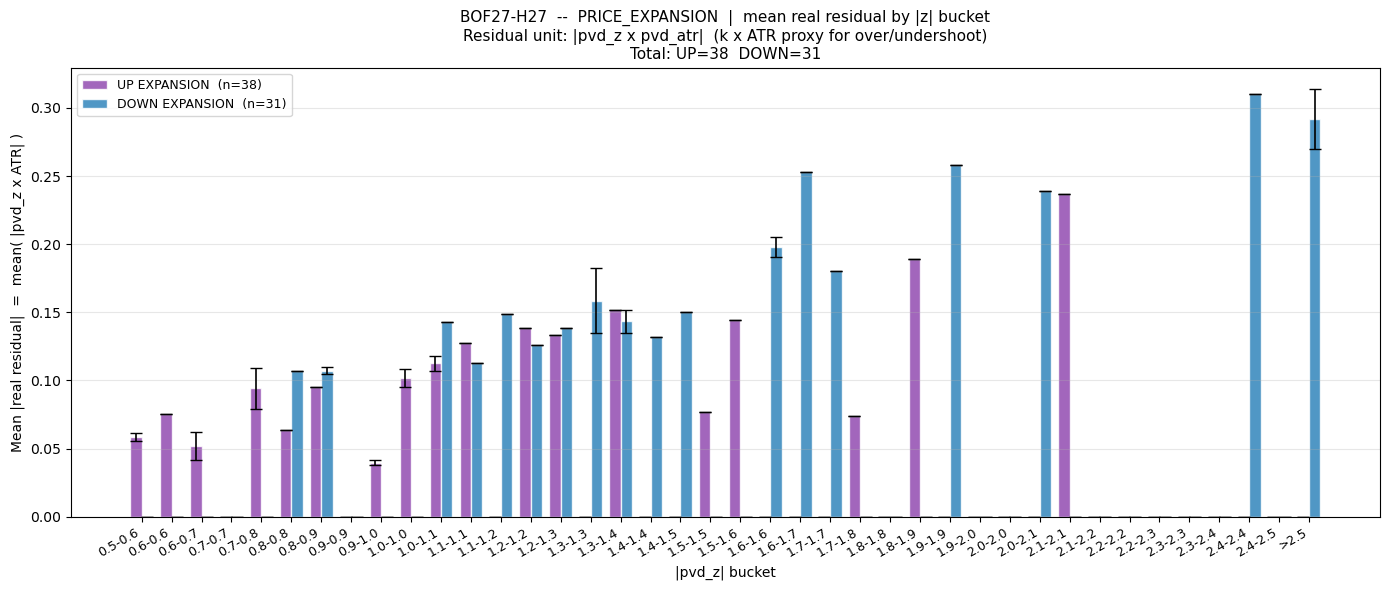

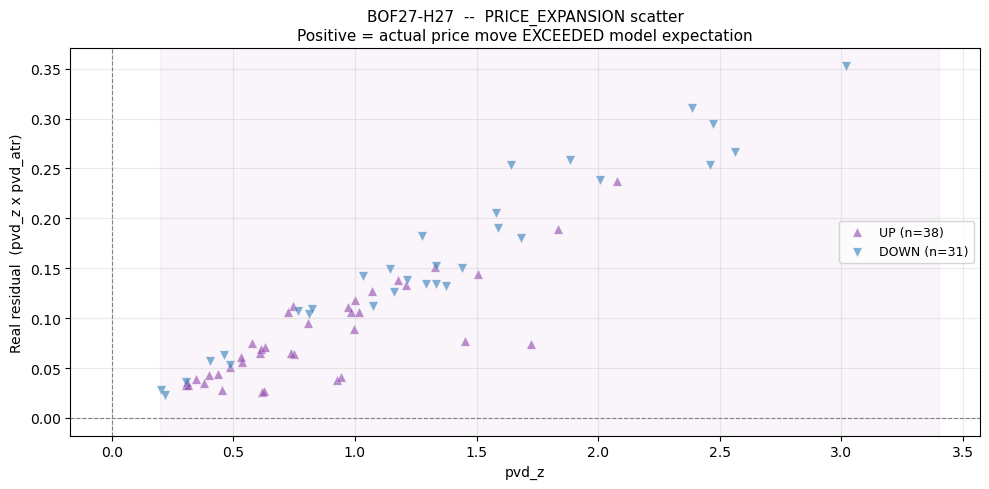


  INSTRUMENT : BOH27-K27  (SPREAD)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (179 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 55   SUCCESS=12  FAILURE=9  UNRESOLVED=34
    UP_TREND_EXHAUSTION         : S=9  F=6  U=14  total=29
    DOWN_TREND_EXHAUSTION       : S=3  F=3  U=20  total=26

  -- EXPANSION SIGNALS -------------------------------------------
    UP_PRICE_

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,55,0.836,"[0.800, 0.909]",1.000,0.911,--,1.000,46,9,0,0,False
1,0.400,50,0.820,"[0.780, 0.902]",0.891,0.854,-0.140,0.980,41,9,5,0,False
2,0.500,47,0.809,"[0.767, 0.891]",0.826,0.817,-0.182,0.967,38,9,8,0,False
3,0.600,39,0.769,"[0.725, 0.861]",0.652,0.706,-0.283,0.920,30,9,16,0,False
4,0.700,37,0.784,"[0.737, 0.857]",0.630,0.699,-0.204,0.937,29,8,17,1,False
5,0.800,35,0.771,"[0.716, 0.850]",0.587,0.667,-0.232,0.922,27,8,19,1,False
6,0.900,27,0.778,"[0.714, 0.880]",0.457,0.575,-0.156,0.930,21,6,25,3,False
7,1.000,25,0.800,"[0.717, 0.946]",0.435,0.563,-0.090,0.957,20,5,26,4,False
8,1.100,22,0.773,"[0.647, 0.931]",0.370,0.500,-0.140,0.924,17,5,29,4,False
9,1.200,18,0.722,"[0.583, 0.905]",0.283,0.406,-0.215,0.864,13,5,33,4,False


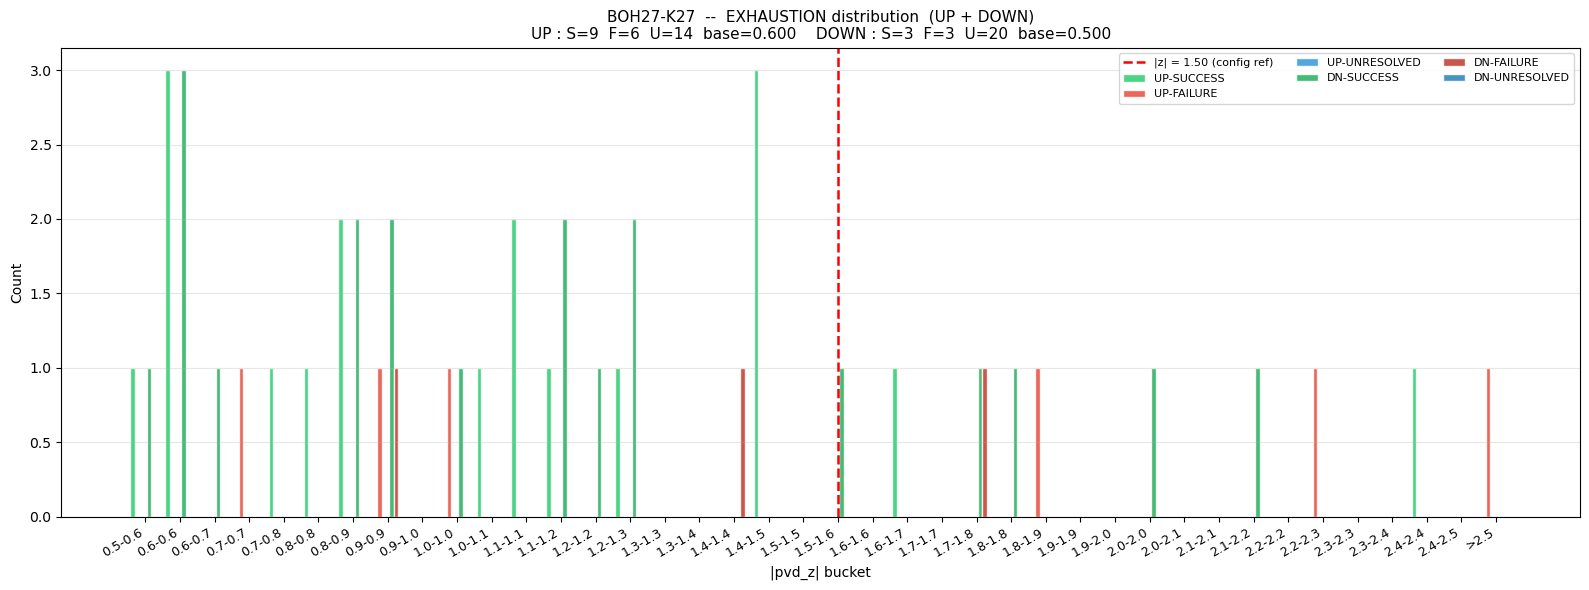

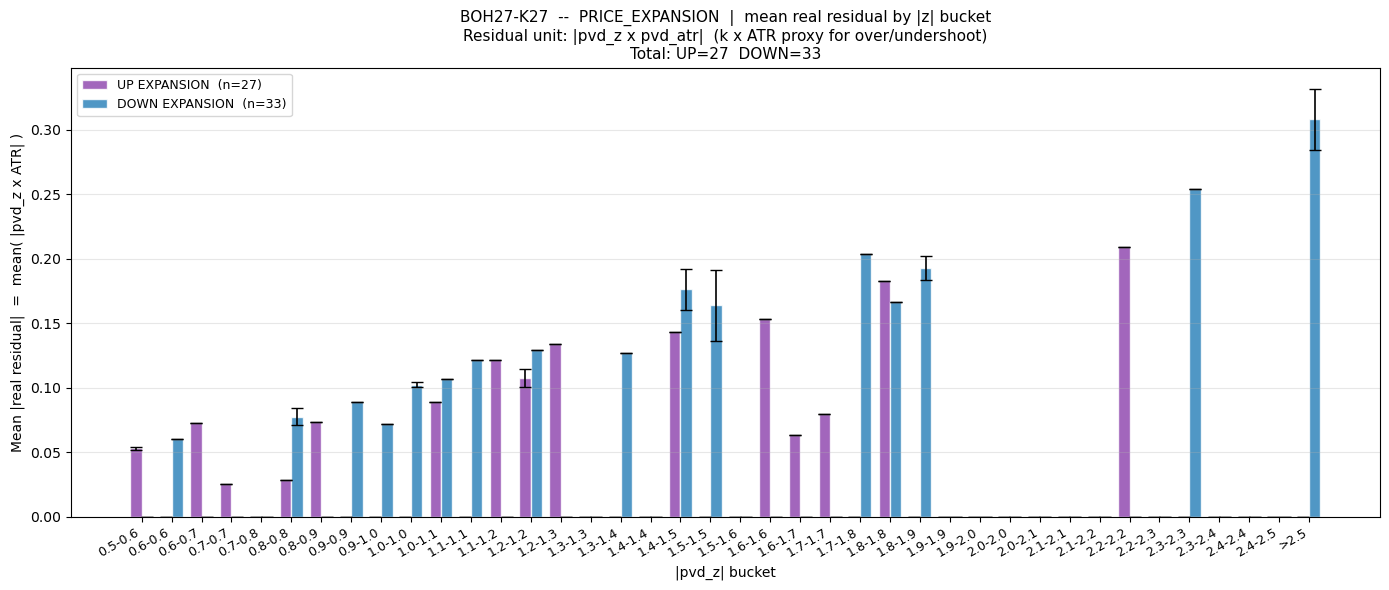

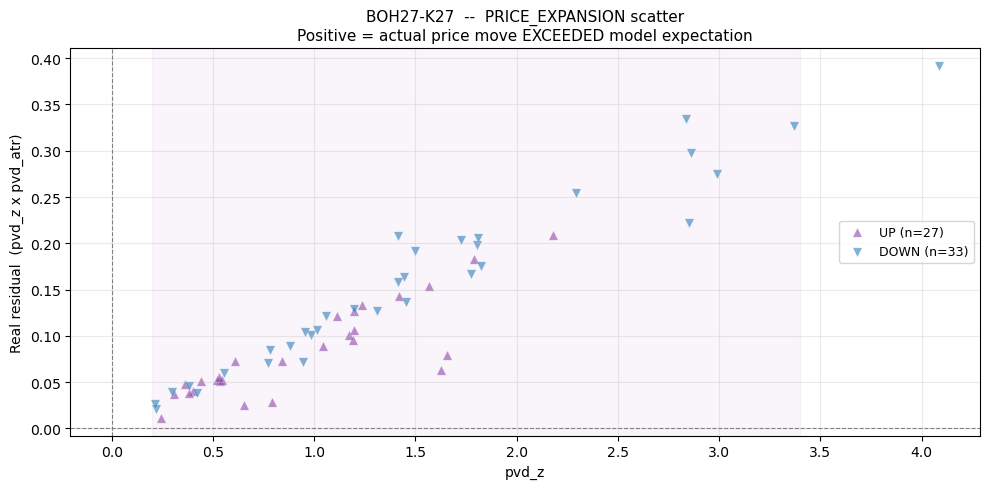


  INSTRUMENT : BOK27-N27  (SPREAD)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (181 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 60   SUCCESS=12  FAILURE=13  UNRESOLVED=35
    UP_TREND_EXHAUSTION         : S=10  F=6  U=20  total=36
    DOWN_TREND_EXHAUSTION       : S=2  F=7  U=15  total=24

  -- EXPANSION SIGNALS -------------------------------------------
    UP_PRIC

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,60,0.783,"[0.633, 0.909]",1.000,0.879,--,1.000,47,13,0,0,False
1,0.400,53,0.792,"[0.647, 0.909]",0.894,0.840,0.061,1.012,42,11,5,2,False
2,0.500,46,0.783,"[0.646, 0.900]",0.766,0.774,-0.003,0.999,36,10,11,3,False
3,0.600,41,0.780,"[0.675, 0.897]",0.681,0.727,-0.010,0.996,32,9,15,4,False
4,0.700,35,0.743,"[0.600, 0.882]",0.553,0.634,-0.116,0.948,26,9,21,4,False
5,0.800,30,0.700,"[0.538, 0.862]",0.447,0.545,-0.202,0.894,21,9,26,4,False
6,0.900,25,0.720,"[0.577, 0.889]",0.383,0.500,-0.130,0.919,18,7,29,6,False
7,1.000,23,0.783,"[0.682, 0.959]",0.383,0.514,-0.001,0.999,18,5,29,8,False
8,1.100,18,0.833,"[0.675, 1.000]",0.319,0.462,0.079,1.064,15,3,32,10,False
9,1.200,16,0.812,"[0.615, 1.000]",0.277,0.413,0.043,1.037,13,3,34,10,False


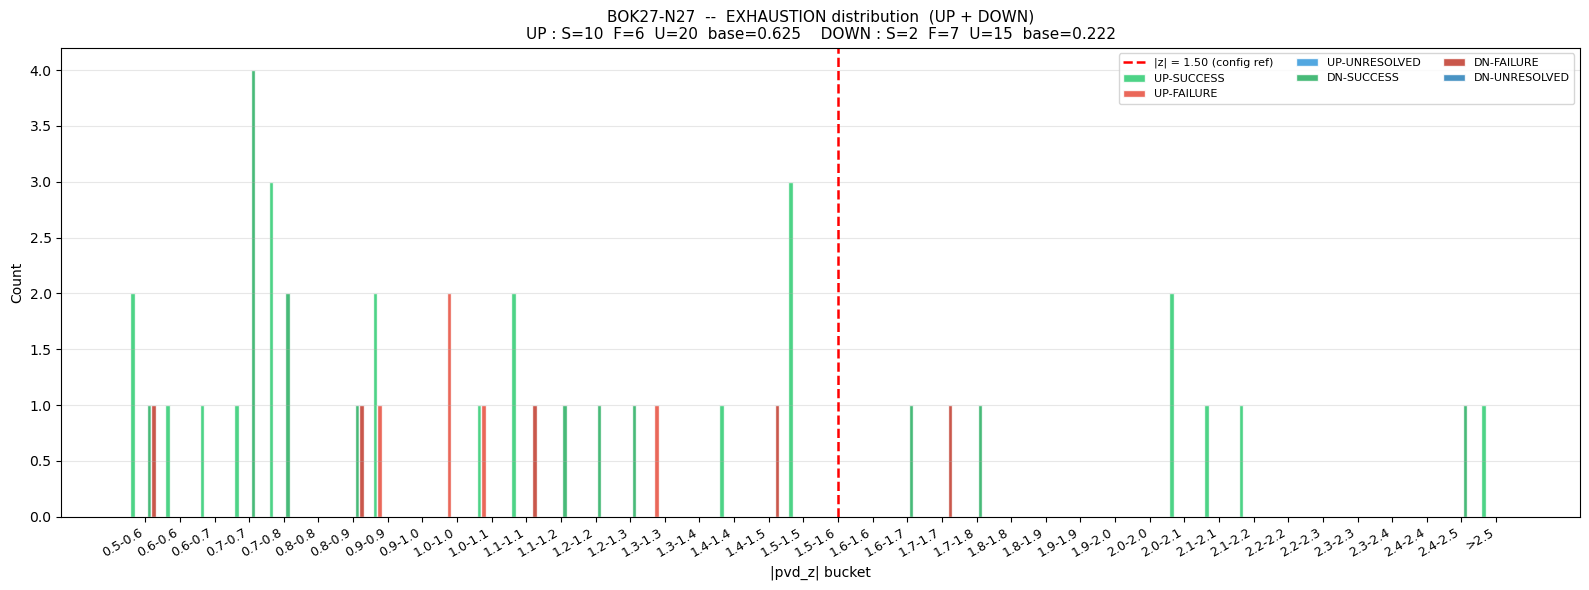

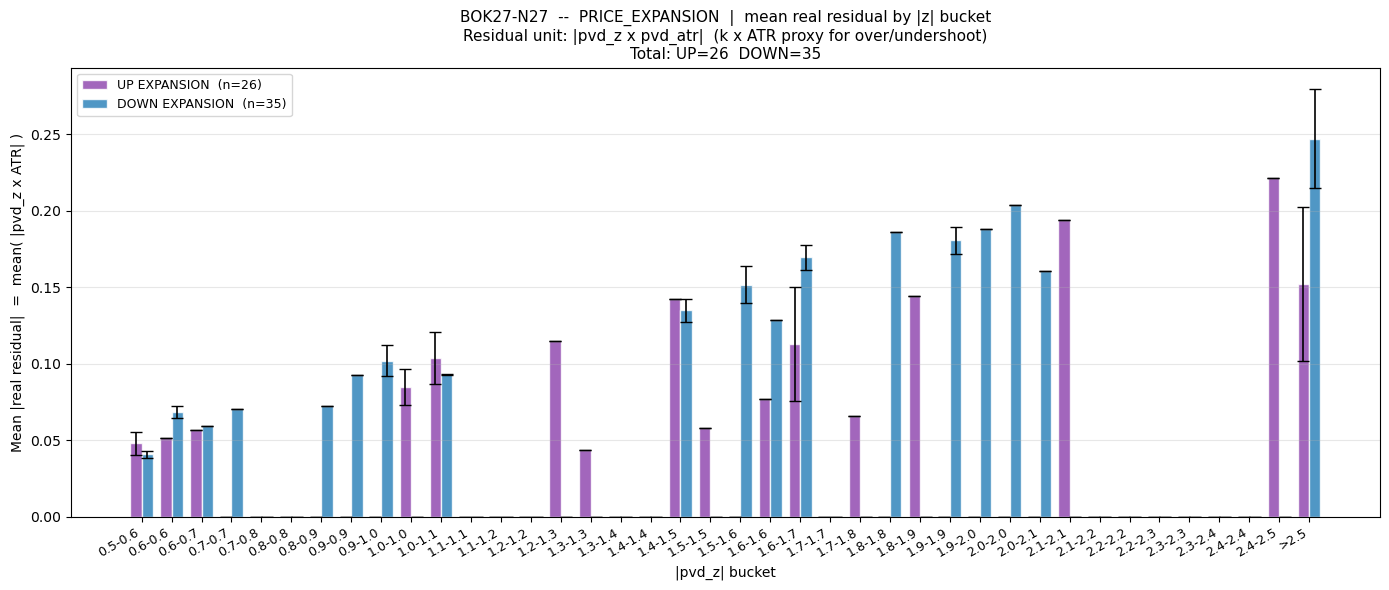

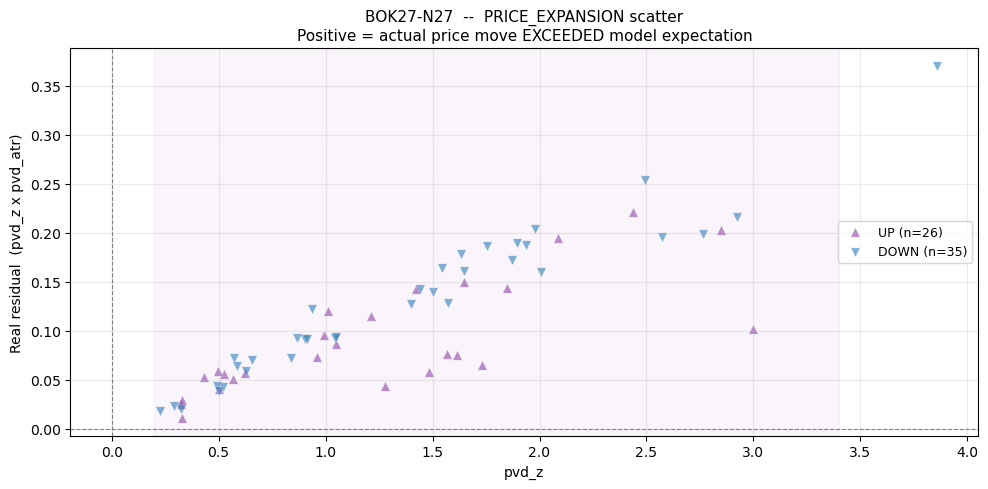


########################################################################
#  STRUCTURE : JUMBO  --  BO
########################################################################

  INSTRUMENT : BOV26-F27  (JUMBO)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (179 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 63   SUCCESS=18  FAILURE=26  UNRESOLVED=19
    UP_TREND_EXHAUSTION

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,63,0.587,"[0.429, 0.738]",1.000,0.740,--,1.000,37,26,0,0,False
1,0.400,58,0.552,"[0.390, 0.694]",0.865,0.674,-0.246,0.939,32,26,5,0,False
2,0.500,54,0.556,"[0.378, 0.723]",0.811,0.659,-0.158,0.946,30,24,7,2,False
3,0.600,47,0.574,"[0.376, 0.721]",0.730,0.643,-0.045,0.978,27,20,10,6,False
4,0.700,38,0.605,"[0.415, 0.750]",0.622,0.613,0.045,1.031,23,15,14,11,False
5,0.800,36,0.583,"[0.410, 0.742]",0.568,0.575,-0.009,0.993,21,15,16,11,False
6,0.900,33,0.576,"[0.400, 0.738]",0.514,0.543,-0.025,0.980,19,14,18,12,False
7,1.000,23,0.696,"[0.500, 0.875]",0.432,0.533,0.167,1.184,16,7,21,19,False
8,1.100,20,0.700,"[0.500, 0.872]",0.378,0.491,0.156,1.192,14,6,23,20,False
9,1.200,20,0.700,"[0.500, 0.872]",0.378,0.491,0.156,1.192,14,6,23,20,False


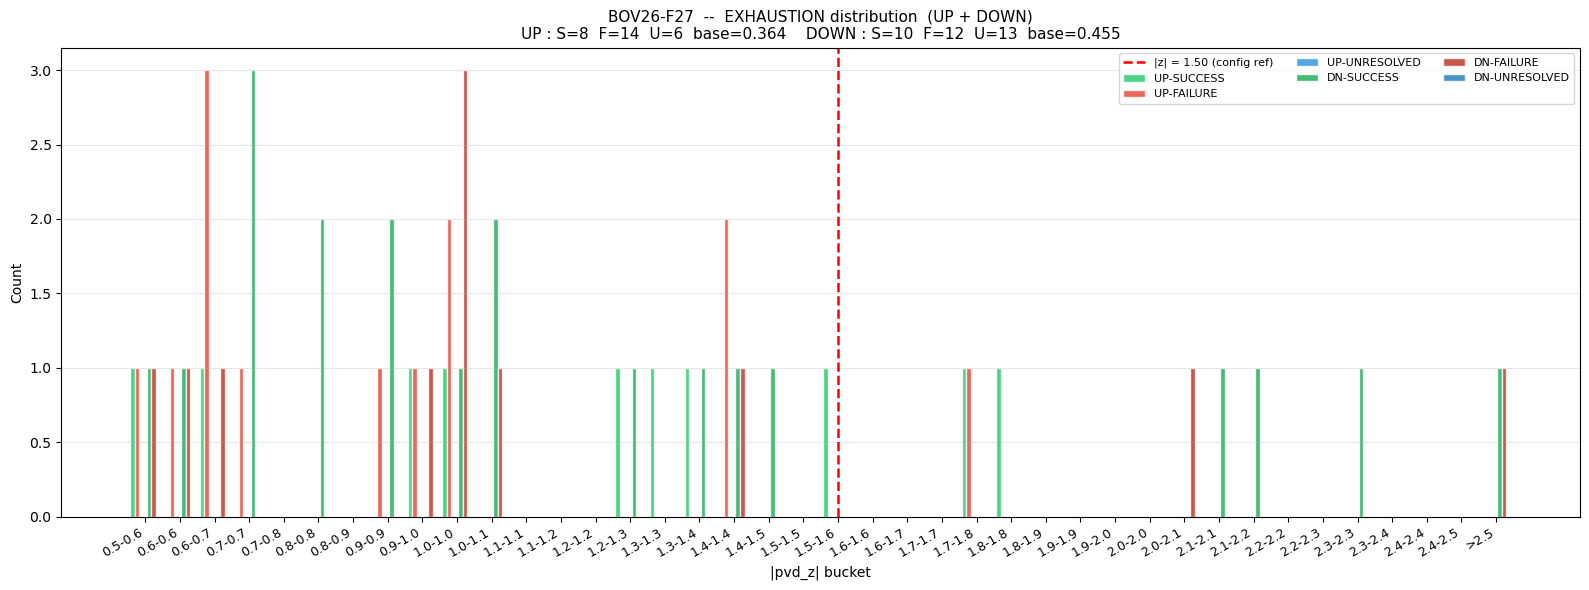

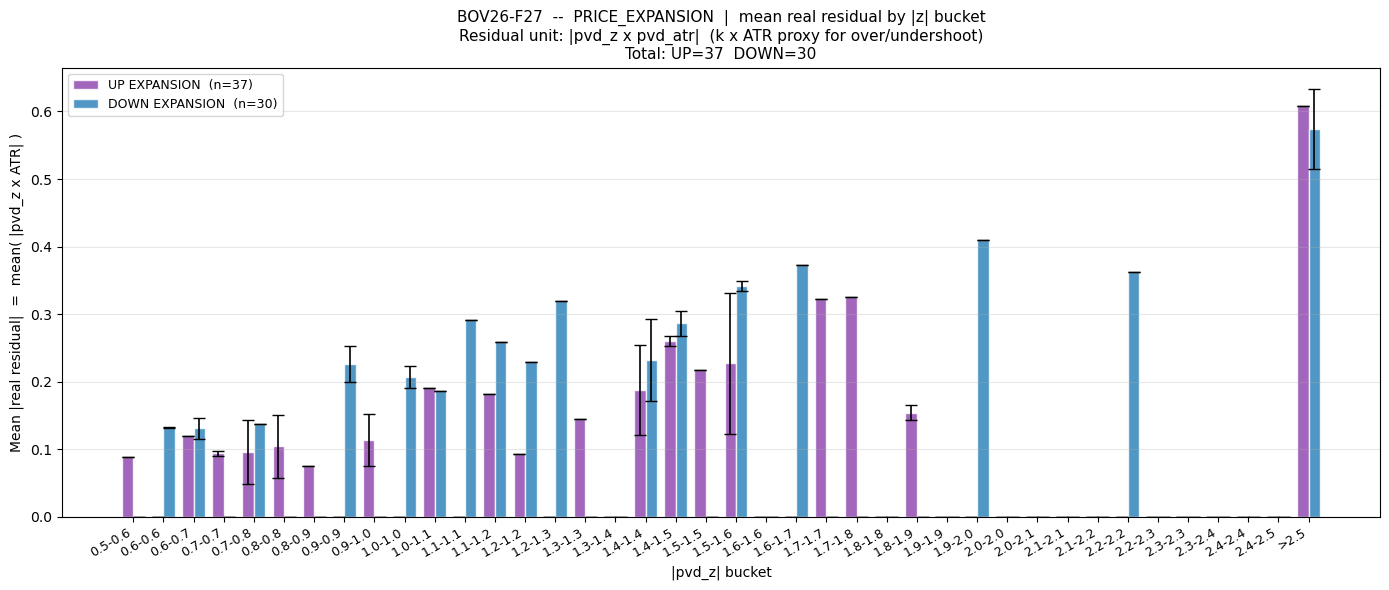

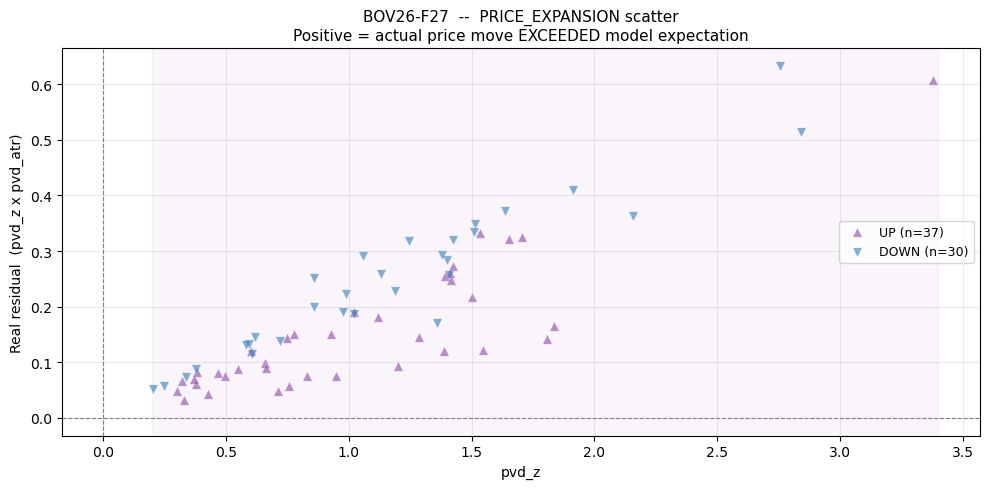


  INSTRUMENT : BOV26-H27  (JUMBO)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (109 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 35   SUCCESS=10  FAILURE=11  UNRESOLVED=14
    UP_TREND_EXHAUSTION         : S=6  F=4  U=4  total=14
    DOWN_TREND_EXHAUSTION       : S=4  F=7  U=10  total=21

  -- EXPANSION SIGNALS -------------------------------------------
    UP_PRICE_E

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,35,0.686,"[0.514, 0.714]",1.000,0.814,--,1.000,24,11,0,0,False
1,0.400,35,0.686,"[0.514, 0.714]",1.000,0.814,--,1.000,24,11,0,0,False
2,0.500,28,0.821,"[0.731, 0.862]",0.958,0.885,0.585,1.198,23,5,1,6,False
3,0.600,25,0.800,"[0.696, 0.840]",0.833,0.816,0.389,1.167,20,5,4,6,False
4,0.700,24,0.792,"[0.667, 0.833]",0.792,0.792,0.337,1.155,19,5,5,6,False
5,0.800,23,0.783,"[0.667, 0.826]",0.750,0.766,0.289,1.141,18,5,6,6,False
6,0.900,20,0.800,"[0.650, 0.938]",0.667,0.727,0.284,1.167,16,4,8,7,False
7,1.000,17,0.765,"[0.588, 0.929]",0.542,0.634,0.165,1.115,13,4,11,7,False
8,1.100,17,0.765,"[0.588, 0.929]",0.542,0.634,0.165,1.115,13,4,11,7,False
9,1.200,15,0.733,"[0.588, 0.900]",0.458,0.564,0.089,1.069,11,4,13,7,False


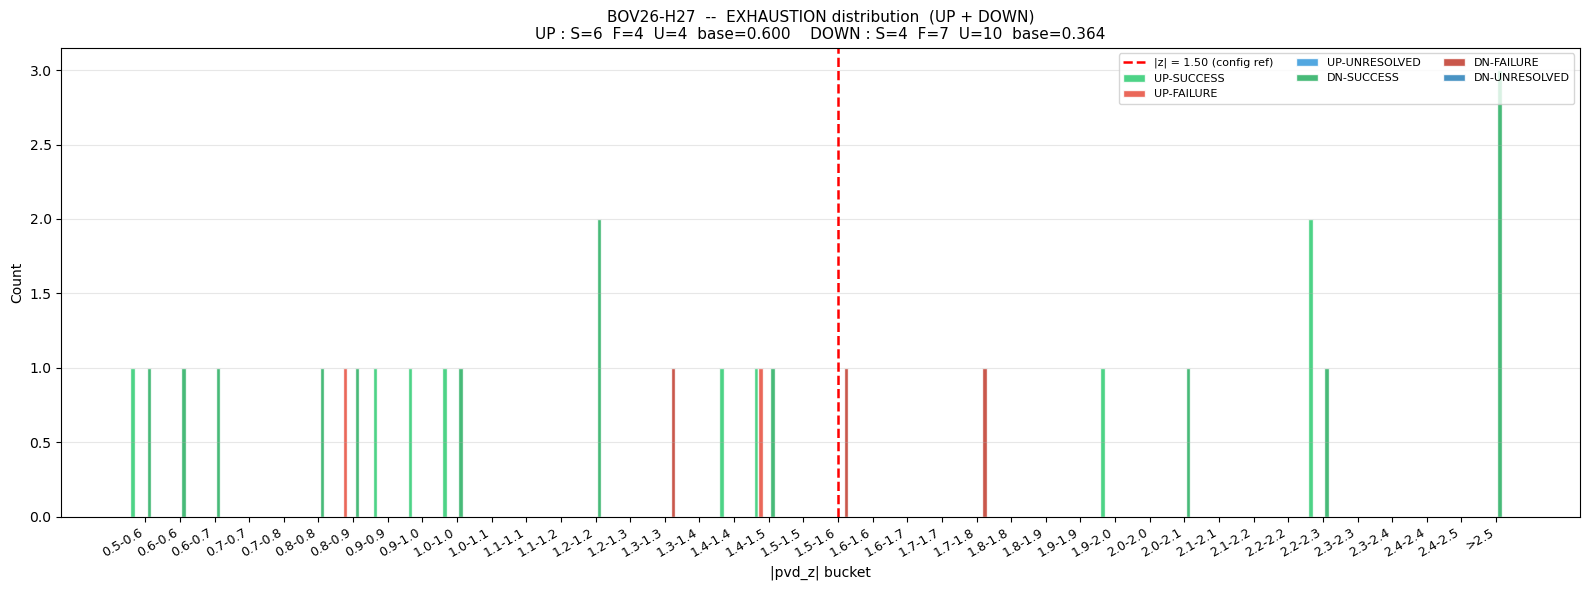

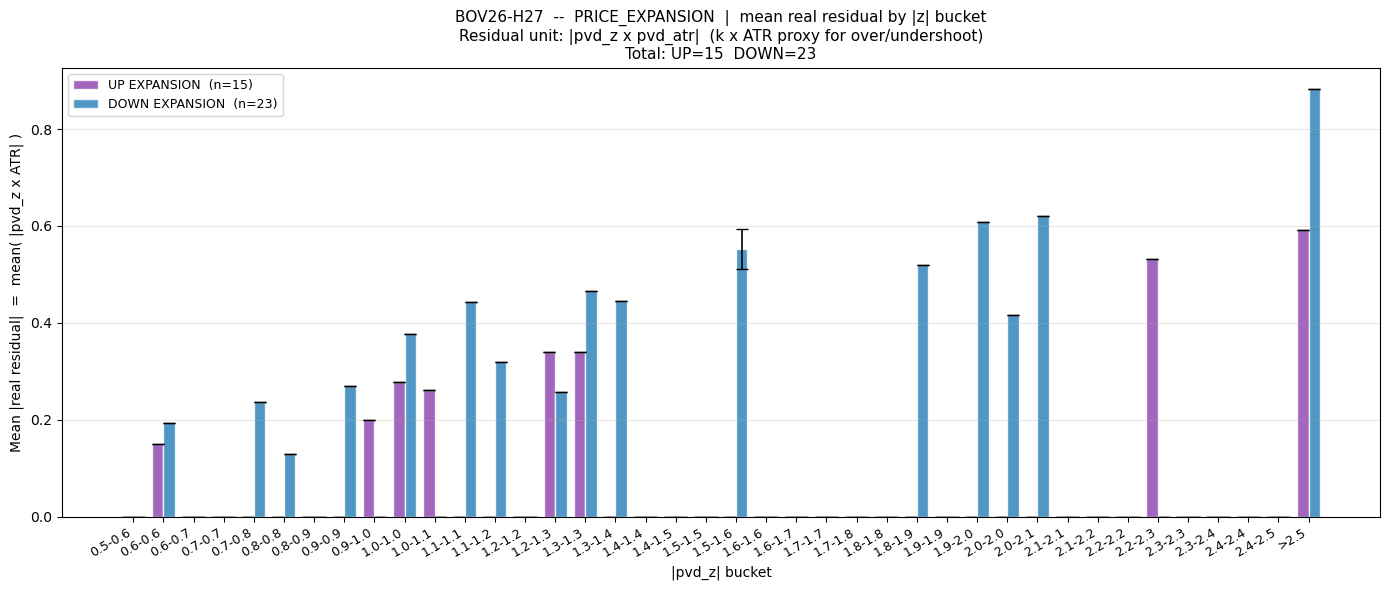

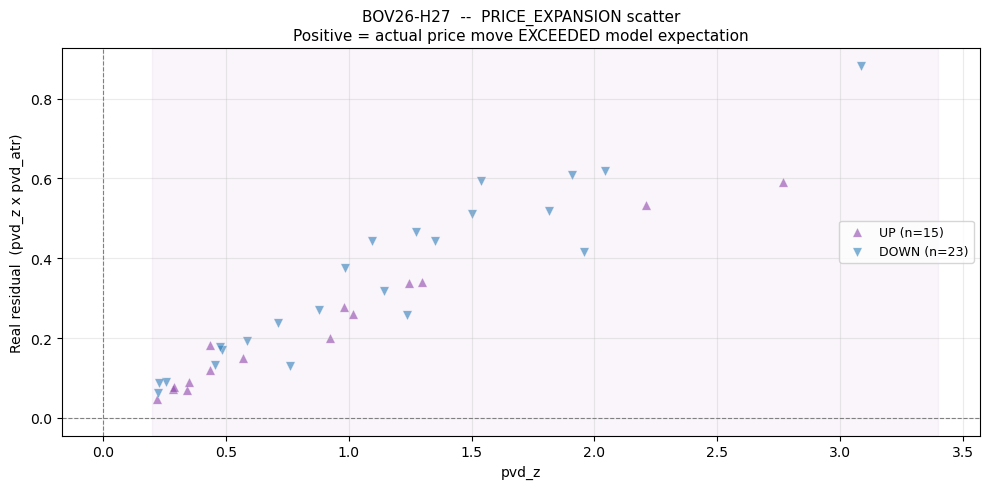


  INSTRUMENT : BOZ26-H27  (JUMBO)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (186 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 62   SUCCESS=19  FAILURE=12  UNRESOLVED=31
    UP_TREND_EXHAUSTION         : S=11  F=10  U=12  total=33
    DOWN_TREND_EXHAUSTION       : S=8  F=2  U=19  total=29

  -- EXPANSION SIGNALS -------------------------------------------
    UP_PRIC

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,62,0.806,"[0.694, 0.935]",1.000,0.893,--,1.000,50,12,0,0,False
1,0.400,58,0.810,"[0.683, 0.967]",0.940,0.870,0.038,1.005,47,11,3,1,False
2,0.500,51,0.824,"[0.700, 0.981]",0.840,0.832,0.093,1.021,42,9,8,3,False
3,0.600,47,0.830,"[0.723, 0.980]",0.780,0.804,0.105,1.029,39,8,11,4,False
4,0.700,42,0.833,"[0.679, 0.978]",0.700,0.761,0.099,1.033,35,7,15,5,False
5,0.800,36,0.833,"[0.657, 1.000]",0.600,0.698,0.080,1.033,30,6,20,6,False
6,0.900,30,0.867,"[0.712, 1.000]",0.520,0.650,0.148,1.075,26,4,24,8,False
7,1.000,29,0.897,"[0.769, 1.000]",0.520,0.658,0.214,1.112,26,3,24,9,False
8,1.100,26,0.885,"[0.759, 1.000]",0.460,0.605,0.168,1.097,23,3,27,9,False
9,1.200,23,0.913,"[0.818, 1.000]",0.420,0.575,0.207,1.132,21,2,29,10,False


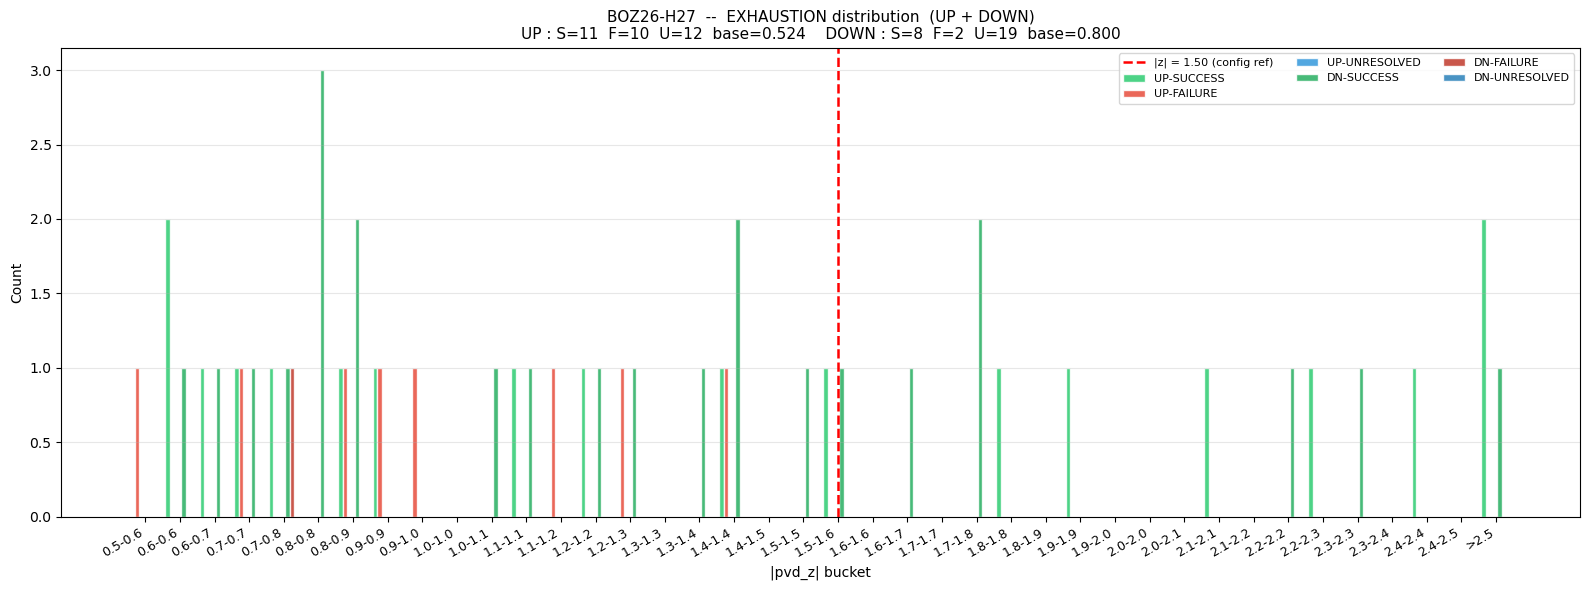

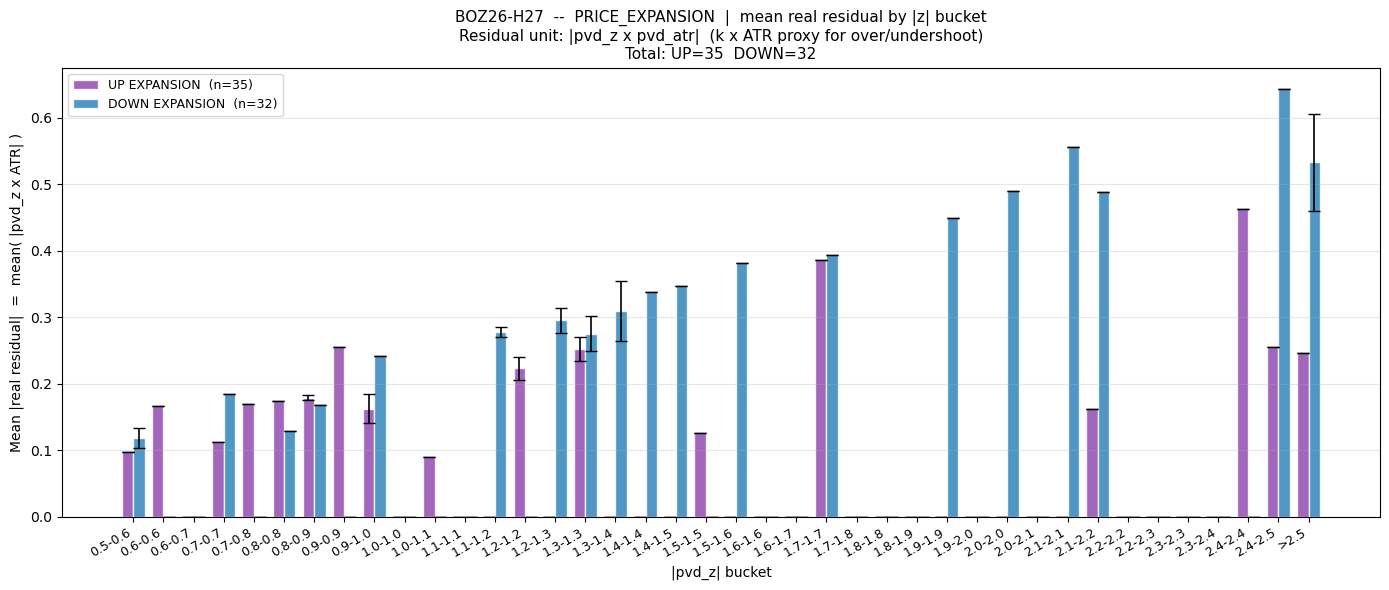

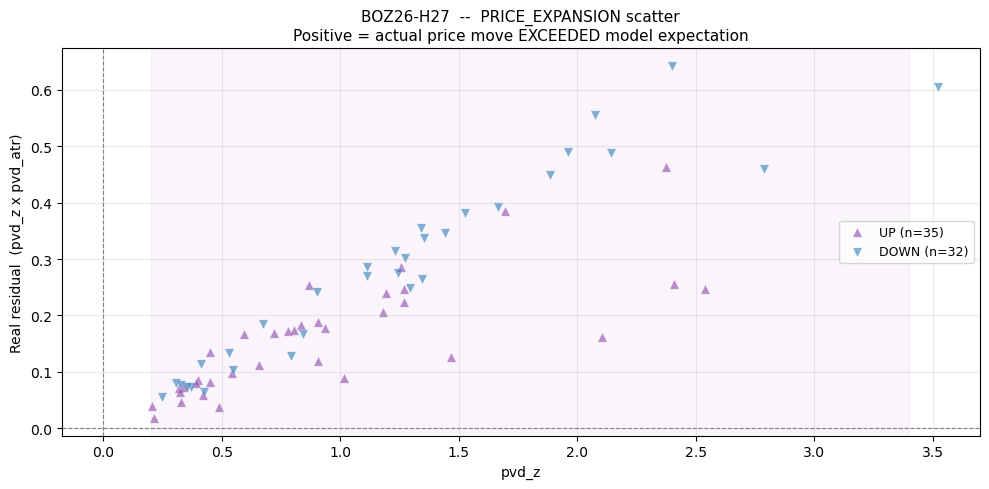


  INSTRUMENT : BOZ26-K27  (JUMBO)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (164 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 58   SUCCESS=13  FAILURE=12  UNRESOLVED=33
    UP_TREND_EXHAUSTION         : S=5  F=6  U=11  total=22
    DOWN_TREND_EXHAUSTION       : S=8  F=6  U=22  total=36

  -- EXPANSION SIGNALS -------------------------------------------
    UP_PRICE_

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,58,0.793,"[0.724, 0.879]",1.000,0.885,--,1.000,46,12,0,0,False
1,0.400,57,0.807,"[0.745, 0.879]",1.000,0.893,0.259,1.018,46,11,0,1,False
2,0.500,50,0.820,"[0.750, 0.890]",0.891,0.854,0.166,1.034,41,9,5,3,False
3,0.600,45,0.844,"[0.762, 0.946]",0.826,0.835,0.236,1.065,38,7,8,5,False
4,0.700,41,0.829,"[0.756, 0.938]",0.739,0.782,0.139,1.046,34,7,12,5,False
5,0.800,37,0.865,"[0.816, 0.974]",0.696,0.771,0.235,1.090,32,5,14,7,False
6,0.900,34,0.853,"[0.791, 0.973]",0.630,0.725,0.176,1.075,29,5,17,7,False
7,1.000,34,0.853,"[0.791, 0.973]",0.630,0.725,0.176,1.075,29,5,17,7,False
8,1.100,31,0.903,"[0.845, 1.000]",0.609,0.727,0.291,1.139,28,3,18,9,False
9,1.200,29,0.931,"[0.870, 1.000]",0.587,0.720,0.341,1.174,27,2,19,10,False


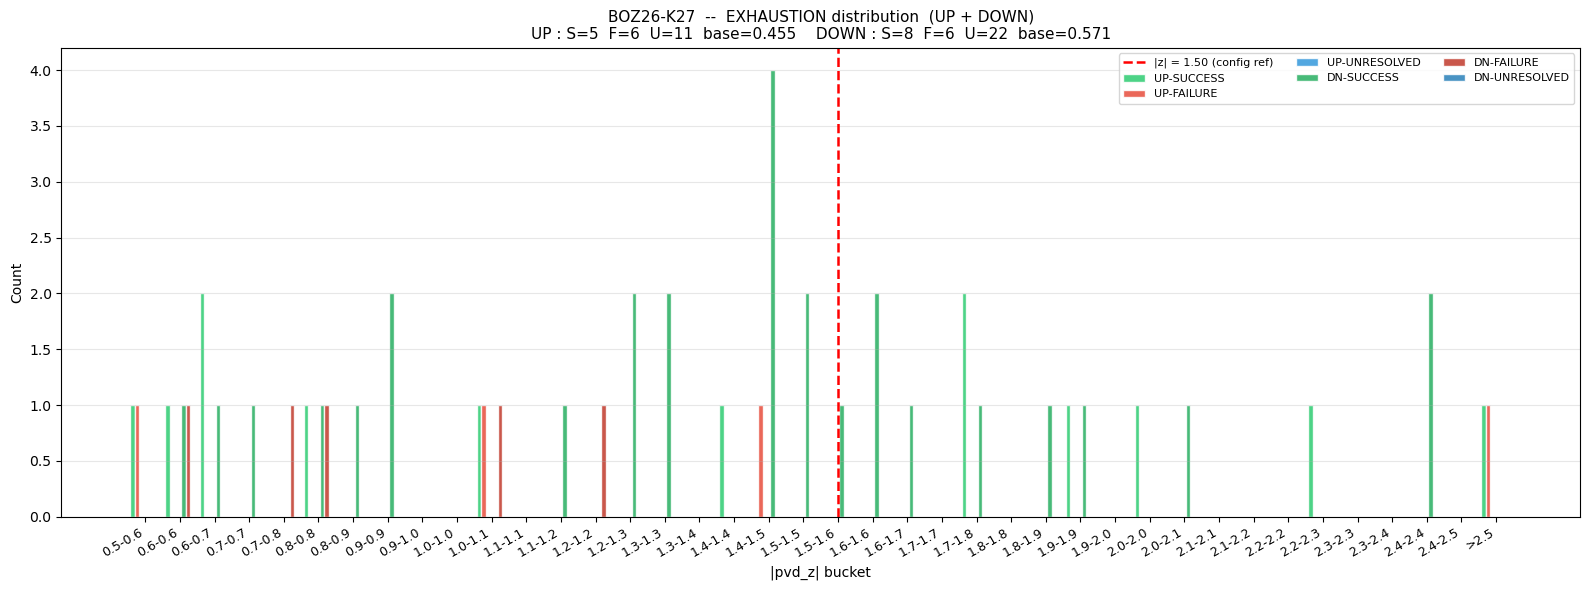

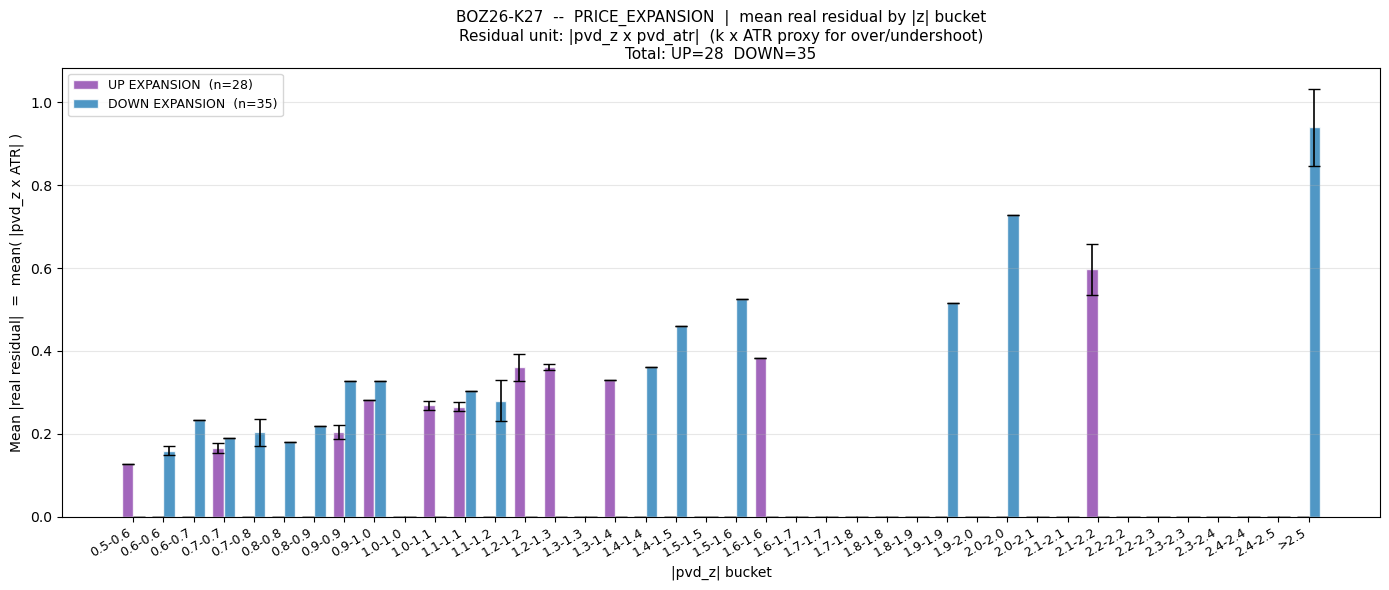

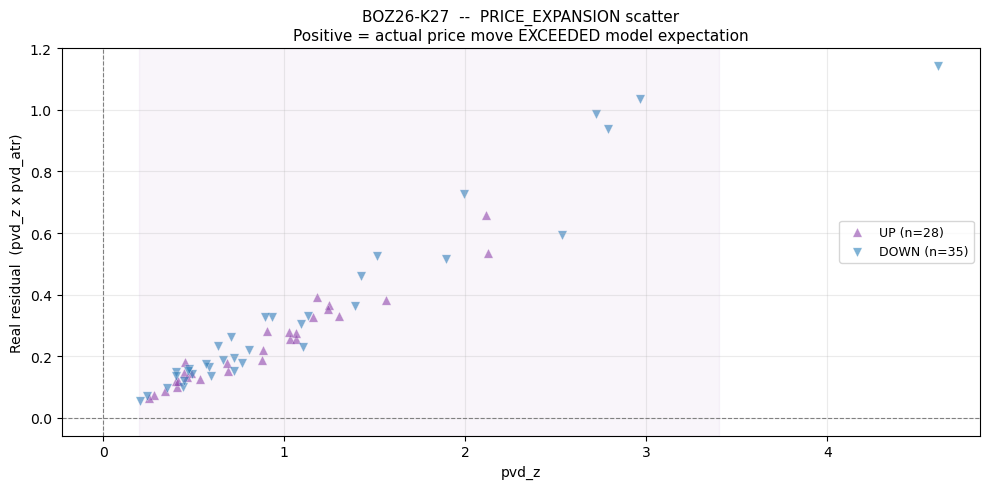


  INSTRUMENT : BOF27-K27  (JUMBO)
  PRODUCT    : BO
  DATA RANGE : 2026-02-23  -->  2026-09-23   (139 bars)
  -- PVD signal params -----------------------------------------
  price_horizon_h   : 3
  volatility_window : 15
  pvd_model_window  : 15
  atr_period        : 10
  -- Exhaustion outcome labelling ------------------------------
  atr_multiplier    : 1.5
  horizon_days      : 10
  merge_unresolved  : True  (UNRESOLVED → SUCCESS)
  -- Exhaustion |z| sweep (combined UP+DOWN) ------------------
  |z| range         : 0.30 --> 3.00  (28 steps)
  config ref |z|    : 1.50
  -- Expansion z range ----------------------------------------
  z_grid_pos        : 0.20 --> 3.40

  -- EXHAUSTION SIGNALS ------------------------------------------
  Total  : 42   SUCCESS=12  FAILURE=6  UNRESOLVED=24
    UP_TREND_EXHAUSTION         : S=11  F=4  U=8  total=23
    DOWN_TREND_EXHAUSTION       : S=1  F=2  U=16  total=19

  -- EXPANSION SIGNALS -------------------------------------------
    UP_PRICE_E

,|z| Threshold,N (UP+DN),Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.300,42,0.857,"[0.702, 0.976]",1.000,0.923,--,1.000,36,6,0,0,False
1,0.400,37,0.865,"[0.688, 0.974]",0.889,0.877,0.060,1.009,32,5,4,1,False
2,0.500,36,0.861,"[0.688, 0.973]",0.861,0.861,0.028,1.005,31,5,5,1,False
3,0.600,32,0.875,"[0.745, 0.971]",0.778,0.824,0.091,1.021,28,4,8,2,False
4,0.700,28,0.893,"[0.688, 0.971]",0.694,0.781,0.144,1.042,25,3,11,3,False
5,0.800,27,0.889,"[0.674, 0.970]",0.667,0.762,0.122,1.037,24,3,12,3,False
6,0.900,26,0.885,"[0.674, 0.967]",0.639,0.742,0.100,1.032,23,3,13,3,False
7,1.000,24,0.875,"[0.667, 0.965]",0.583,0.700,0.059,1.021,21,3,15,3,False
8,1.100,20,0.900,"[0.778, 1.000]",0.500,0.643,0.117,1.050,18,2,18,4,False
9,1.200,17,0.941,"[0.870, 1.000]",0.444,0.604,0.198,1.098,16,1,20,5,False


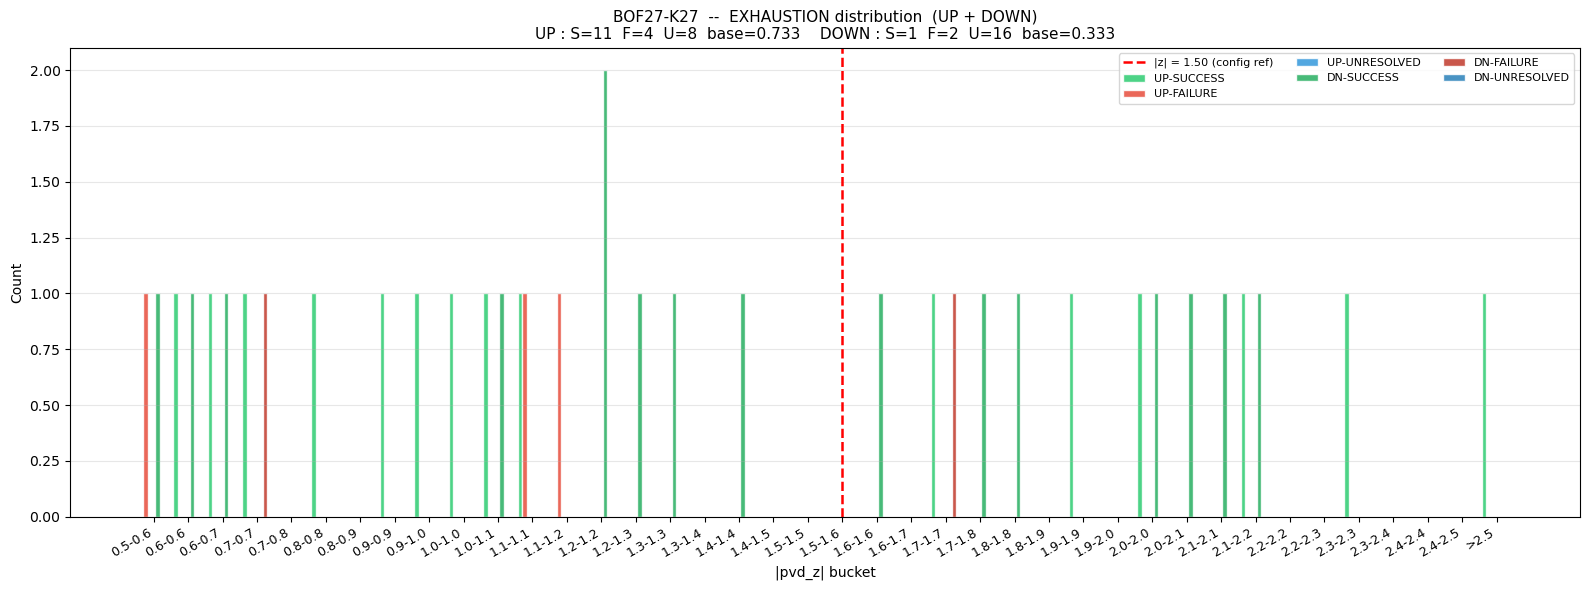

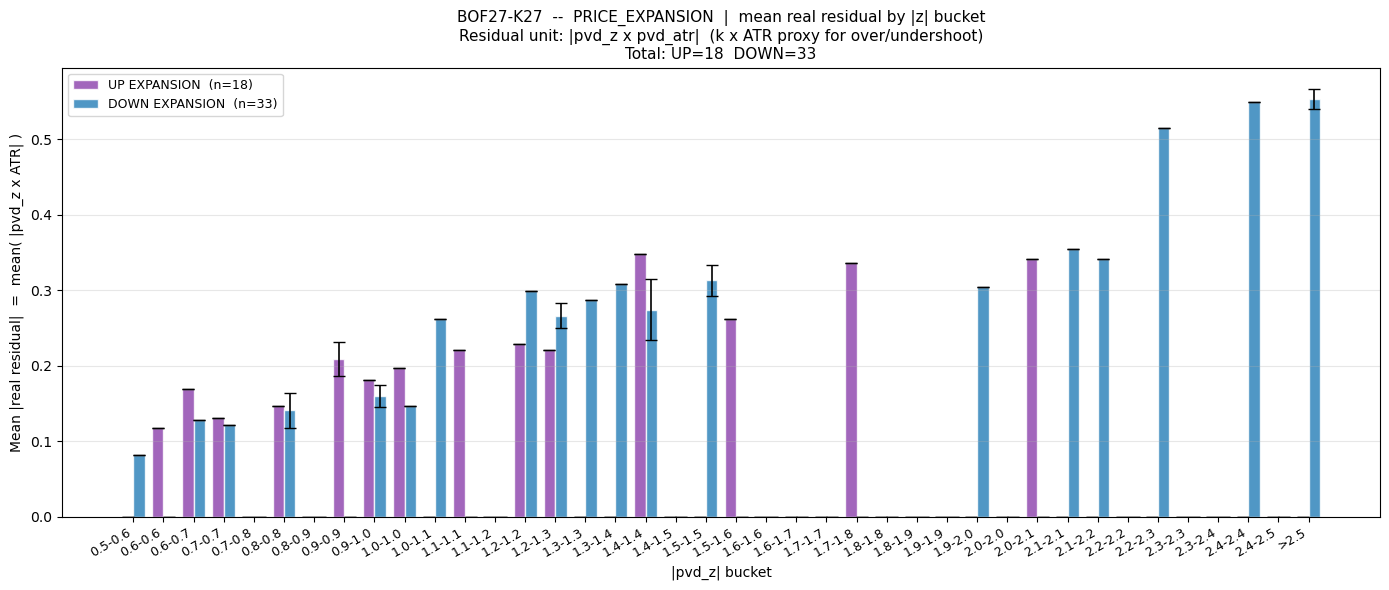

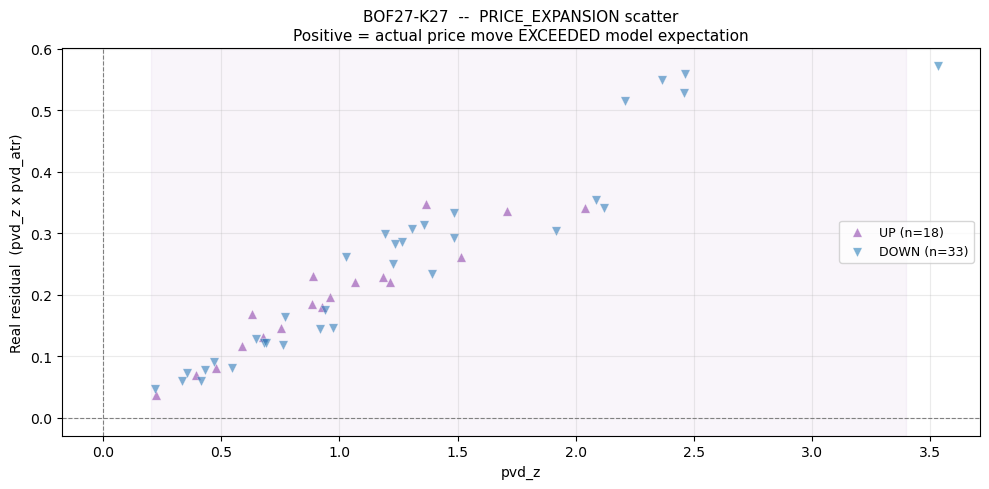


✅ Done — 10 instrument(s) processed


In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 3 — RUN
# Per instrument outputs:
#   • ASCII header with all config/data info
#   • EXHAUSTION table: combined UP+DOWN  F1/Prec/Recall/MCC/Lift
#   • EXHAUSTION distribution chart: 6 bar series by |z| bucket
#   • EXPANSION bar chart: mean |real residual| (k×ATR) per |z| bucket
#   • EXPANSION scatter: pvd_z vs real residual
# ═══════════════════════════════════════════════════════════════════════════
results = run_pvd_threshold_analysis(
    product_code     = PRODUCT_CODE,
    months_back      = MONTHS_BACK,
    z_grid_neg       = Z_GRID_NEG,
    z_grid_pos       = Z_GRID_POS,
    atr_multiplier   = ATR_MULTIPLIER,
    horizon_days     = HORIZON_DAYS,
    front_n          = FRONT_N_INSTR,
    min_signal_count = MIN_N,
    n_bootstrap      = N_BOOTSTRAP,
    random_seed      = RANDOM_SEED,
    show_plots       = True,
)
print(f"\n✅ Done — {len(results)} instrument(s) processed")


In [13]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 4 — CROSS-INSTRUMENT SUMMARY (best F1 threshold per contract)
# ═══════════════════════════════════════════════════════════════════════════
rows = []
for instrument, res in results.items():
    sweep = res["sweep_table"]
    base  = res["base_rate"]
    exp   = res["expansion_df"]
    n_exp = len(exp)
    mean_res = float(exp["_abs_res_atr"].mean()) if n_exp > 0 else float("nan")

    if sweep.empty:
        rows.append({"Instrument": instrument, "|z| Best": "--",
                     "N": 0, "Precision": float("nan"), "Recall": float("nan"),
                     "F1": float("nan"), "MCC": float("nan"), "Lift": float("nan"),
                     "Base Rate": base, "N Expansion": n_exp,
                     "Mean |res| ATR": mean_res})
        continue

    valid = sweep.dropna(subset=["F1"])
    best  = valid.loc[valid["F1"].idxmax()] if len(valid) else sweep.iloc[0]

    rows.append({
        "Instrument"    : instrument,
        "|z| Best"      : round(best["|z| Threshold"], 3),
        "N"             : int(best["N (UP+DN)"]),
        "Precision"     : best["Precision"],
        "Recall"        : best["Recall"],
        "F1"            : best["F1"],
        "MCC"           : best["MCC"],
        "Lift"          : best["Lift"],
        "Base Rate"     : round(base, 3) if np.isfinite(base) else float("nan"),
        "N Expansion"   : n_exp,
        "Mean |res| ATR": round(mean_res, 4) if np.isfinite(mean_res) else float("nan"),
    })

summary = pd.DataFrame(rows)
float_cols = {c: "{:.3f}" for c in ["Precision","Recall","F1","MCC","Lift","Base Rate","Mean |res| ATR"]}

display(HTML(
    f"<h3>Cross-Instrument Summary — Best F1 Threshold (UP+DOWN combined)<br>"
    f"<small>Product: {PRODUCT_CODE} | ATR={ATR_MULTIPLIER} | "
    f"Horizon={HORIZON_DAYS}d | Data={MONTHS_BACK}m</small></h3>"
))
display(
    summary.style
    .format(float_cols, na_rep="--")
    .background_gradient(subset=["F1"],        cmap="RdYlGn", vmin=0.3, vmax=0.7)
    .background_gradient(subset=["Precision"], cmap="Blues",  vmin=0.3, vmax=0.8)
    .background_gradient(subset=["Mean |res| ATR"], cmap="Purples")
    .set_caption(
        f"Best |z| threshold = row with max F1 in the combined UP+DOWN exhaustion sweep\n"
        f"Mean |res| ATR = mean(|pvd_z x pvd_atr|) over all PRICE_EXPANSION rows"
    )
)


,Instrument,|z| Best,N,Precision,Recall,F1,MCC,Lift,Base Rate,N Expansion,Mean |res| ATR
0,BOV26-Z26,0.400000,49,0.653,0.970,0.780,0.269,1.069,0.611,78,0.111
1,BOZ26-F27,0.400000,53,0.830,0.957,0.889,0.362,1.065,0.780,72,0.103
2,BOF27-H27,0.300000,57,0.789,1.000,0.882,--,1.000,0.789,69,0.117
3,BOH27-K27,0.300000,55,0.836,1.000,0.911,--,1.000,0.836,60,0.123
4,BOK27-N27,0.300000,60,0.783,1.000,0.879,--,1.000,0.783,61,0.112
5,BOV26-F27,0.300000,63,0.587,1.000,0.740,--,1.000,0.587,67,0.195
6,BOV26-H27,0.500000,28,0.821,0.958,0.885,0.585,1.198,0.686,38,0.299
7,BOZ26-H27,0.300000,62,0.806,1.000,0.893,--,1.000,0.806,67,0.216
8,BOZ26-K27,0.400000,57,0.807,1.000,0.893,0.259,1.018,0.793,63,0.296
9,BOF27-K27,0.300000,42,0.857,1.000,0.923,--,1.000,0.857,51,0.229
